In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = '/content/drive/MyDrive/Brain Tumor.zip'
extract_path = '/content/BrainTumor'

# Extract only if folder doesn't exist
if not os.path.exists(extract_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print("✅ Dataset extracted.")
else:
    print("Dataset already extracted.")


✅ Dataset extracted.


In [ ]:
train_dir = '/content/BrainTumor/Training'
test_dir  = '/content/BrainTumor/Testing'


In [ ]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

IMG_SIZE = 256

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

test_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

train_data = datasets.ImageFolder(train_dir, transform=train_transforms)
test_data  = datasets.ImageFolder(test_dir, transform=test_transforms)

train_loader = DataLoader(train_data, batch_size=32, shuffle=True)
test_loader  = DataLoader(test_data, batch_size=32, shuffle=False)

num_classes = len(train_data.classes)
print(f"Detected {num_classes} classes: {train_data.classes}")


Detected 4 classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

model = models.resnet50(pretrained=True)

# Freeze earlier layers if dataset is small
for param in model.parameters():
    param.requires_grad = False

# Replace final layer
in_features = model.fc.in_features
model.fc = nn.Linear(in_features, num_classes)

model = model.to(device)


Device: cuda


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet50_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet50_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:01<00:00, 84.9MB/s]


In [ ]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=1e-3)


In [ ]:
from tqdm import tqdm

num_epochs = 15
best_acc = 0.0

for epoch in range(num_epochs):
    model.train()
    running_loss, correct, total = 0.0, 0, 0

    for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs}"):
        imgs, labels = imgs.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        total += labels.size(0)
        correct += predicted.eq(labels).sum().item()

    train_acc = 100 * correct / total
    avg_loss = running_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_loss:.4f}, Train Acc: {train_acc:.2f}%")

    # Evaluate on test set
    model.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)
            outputs = model(imgs)
            _, predicted = outputs.max(1)
            total += labels.size(0)
            correct += predicted.eq(labels).sum().item()
    test_acc = 100 * correct / total
    print(f"Test Accuracy: {test_acc:.2f}%")

    # Save best model
    if test_acc > best_acc:
        best_acc = test_acc
        torch.save(model.state_dict(), "/content/best_resnet50.pth")
        print("✅ Saved new best model.")

# Load best model for final evaluation
model.load_state_dict(torch.load("/content/best_resnet50.pth"))
model.eval()


Epoch 1/15: 100%|██████████| 179/179 [00:51<00:00,  3.47it/s]


Epoch [1/15], Loss: 0.6825, Train Acc: 75.02%
Test Accuracy: 77.27%
✅ Saved new best model.


Epoch 2/15: 100%|██████████| 179/179 [00:49<00:00,  3.60it/s]


Epoch [2/15], Loss: 0.4292, Train Acc: 84.61%
Test Accuracy: 81.92%
✅ Saved new best model.


Epoch 3/15: 100%|██████████| 179/179 [00:50<00:00,  3.53it/s]


...

Epoch 14/15: 100%|██████████| 179/179 [00:53<00:00,  3.34it/s]


Epoch [14/15], Loss: 0.2784, Train Acc: 90.32%
Test Accuracy: 87.72%
✅ Saved new best model.


Epoch 15/15: 100%|██████████| 179/179 [00:52<00:00,  3.43it/s]


Epoch [15/15], Loss: 0.2793, Train Acc: 90.02%
Test Accuracy: 88.79%
✅ Saved new best model.


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

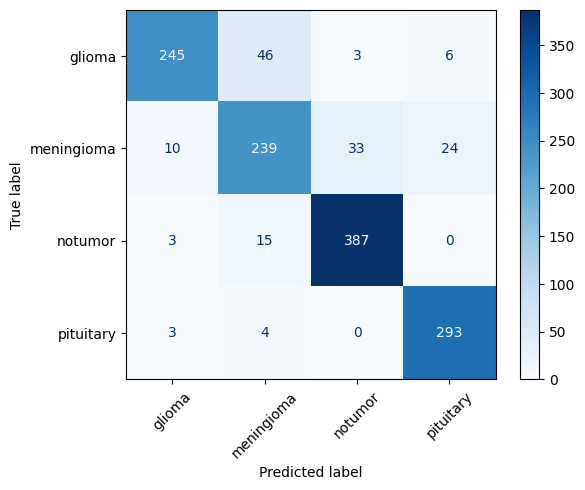

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

y_true, y_pred = [], []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)
        outputs = model(imgs)
        preds = torch.argmax(outputs, dim=1)
        y_true.extend(labels.numpy())
        y_pred.extend(preds.cpu().numpy())

cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(cm, display_labels=train_data.classes)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.show()


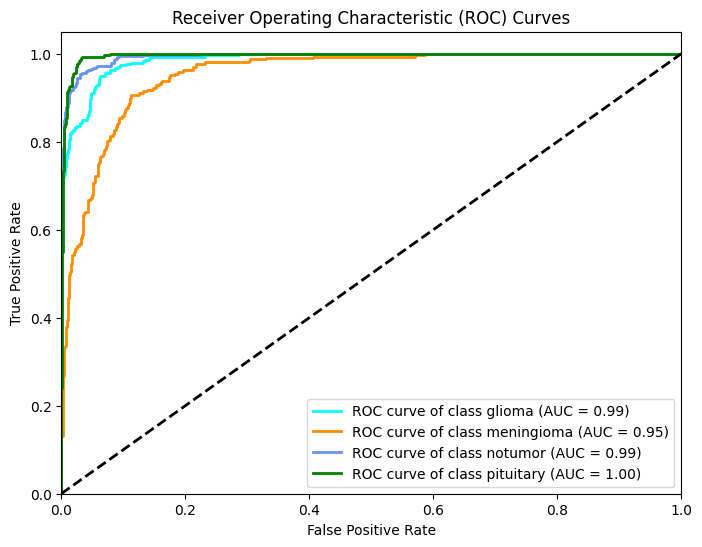

In [ ]:
import torch
import numpy as np
from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt
from itertools import cycle

# Ensure model is in evaluation mode
model.eval()

# Get true labels and predicted probabilities
y_true = []
y_score = []

with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Collecting ROC data"):
        imgs = imgs.to(device)
        outputs = model(imgs)
        probs = torch.softmax(outputs, dim=1)  # Get probabilities
        y_true.extend(labels.cpu().numpy())
        y_score.extend(probs.cpu().numpy())

y_true = np.array(y_true)
y_score = np.array(y_score)

# Binarize labels for multi-class ROC
n_classes = len(train_data.classes)
y_true_bin = label_binarize(y_true, classes=list(range(n_classes)))

# Compute ROC curve and AUC for each class
fpr, tpr, roc_auc = dict(), dict(), dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_true_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and AUC
fpr["micro"], tpr["micro"], _ = roc_curve(y_true_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# Plot all ROC curves
plt.figure(figsize=(8, 6))
colors = cycle(["aqua", "darkorange", "cornflowerblue", "green", "red", "purple"])

for i, color in zip(range(n_classes), colors):
    plt.plot(
        fpr[i],
        tpr[i],
        color=color,
        lw=2,
        label=f"ROC curve of class {train_data.classes[i]} (AUC = {roc_auc[i]:0.2f})"
    )

plt.plot([0, 1], [0, 1], "k--", lw=2)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Receiver Operating Characteristic (ROC) Curves")
plt.legend(loc="lower right")
plt.show()

In [ ]:
save_path = '/content/drive/MyDrive/best_resnet50.pth'
torch.save(model.state_dict(), save_path)
print("✅ Model weights saved successfully to Google Drive!")


✅ Model weights saved successfully to Google Drive!


In [ ]:
save_full_path = '/content/drive/MyDrive/resnet50_full_model.pth'
torch.save(model, save_full_path)
print("✅ Full model (architecture + weights) saved successfully!")


✅ Full model (architecture + weights) saved successfully!


In [ ]:
import torch
from torchvision.models import resnet

# Allow ResNet class
torch.serialization.add_safe_globals([resnet.ResNet])

# Now safely load your full model
model_path = '/content/drive/MyDrive/resnet50_full_model.pth'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = torch.load(model_path, map_location=device, weights_only=False)
model.to(device)
model.eval()

print("✅ Full model loaded successfully!")



In [ ]:
# 4️⃣ Define preprocessing (must match training transforms)
from torchvision import transforms

# 4️⃣ Define preprocessing (must match training transforms)
transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

transform = transforms.Compose([
    transforms.Resize((256, 256)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])


In [ ]:
# 5️⃣ Load your image from Google Drive and preprocess it
from PIL import Image
img_path = '/content/drive/MyDrive/meningioma_tumor(126).jpg'  # update path if different
image = Image.open(img_path).convert("RGB")
image = transform(image).unsqueeze(0).to(device)  # Add batch dimension


In [ ]:
# 6️⃣ Predict tumor type
with torch.no_grad():
    outputs = model(image)
    _, predicted = torch.max(outputs, 1)

# Classes used during training (must be in the same order)
classes = ["glioma_tumor", "meningioma_tumor", "no_tumor", "pituitary_tumor"]

print(f"🧩 Predicted Tumor Type: {classes[predicted.item()]}")
